# Supplementary material: AS-SNC notebook

Companion notebook to the manuscript *A Spectral Active-Set Method for Second-Order Cone Programs with Shared Norm Coupling*. It contains the AS-SNC implementation, the problem generator, the embedded Fama–French data, every benchmark experiment and the code that produces each figure and table of the paper. The outputs stored below are those of the archived run in `AS_SNC_Reproduction_Results.zip`.

| Paper | Notebook output |
|---|---|
| Algorithm 1 | `as_snc` in the AS-SNC implementation cell |
| Example 1 | counterexample check in the additional numerical checks |
| Table 2, Figure 1 | dimension sweep, `summary.json`, `fig_scaling.png` |
| Figure 2 | `fig_convergence.png` |
| Figure 3 | `fig_scale_invariance.png` |
| Figure 4 | `fig_active_count.png` |
| Figure 5 | tolerance sweep, `fig_pareto.png` |
| Figure 6 | conditioning sweep, `fig_conditioning.png` |
| Figure 7 | synthetic portfolio, `portfolio.json`, `fig_portfolio.png` |
| Table 3, Figure 8 | Fama–French benchmark, `summary.json`, `fig_famafrench.png` |
| Table 4 | solver-only timing cell, `solver_only.json` |


This notebook uses a fixed random generator, seeds, dimensions and Fama–French input data. The archived run records the platform and library versions but not the processor model; the last cell before the archive step records it on the machine where the notebook is run. AS-SNC caches the rotated directions, uses the fixed-point update for up to 20 steps per working set, then applies a reduced Newton KKT correction when necessary. Every returned AS-SNC solution is checked; conic fallback is explicitly identified.

The comparisons retain every finite backend result. Accuracy is reported separately as scaled feasibility violation, relative objective difference from an independent tight SCS solution, and KKT residuals. Clarabel cross-checks the reference objective. The common benchmark target is feasibility ≤ 10⁻⁷ and relative objective difference ≤ 10⁻⁶. No result is removed solely because it fails a reconstructed stationarity threshold. Requested backend tolerances are 10⁻⁹ for the default comparisons; they are not identical stopping rules.

Timings include AS-SNC preprocessing, iteration and final check, or CVXPY construction, canonicalization and backend solve. The common external evaluation is outside both timings. Each timed call follows a warmup. BLAS is limited to one thread; Gurobi and MOSEK are also configured for one thread. Raw attempts, failures, input hashes, accuracy measures and timings are exported to `as_snc_results/`.

MOSEK requires an externally configured licence. Gurobi's restricted licence may exclude larger models. Unavailable measurements remain unavailable; no forecasts are substituted. No credentials are embedded.

For a fresh Colab environment, install `numpy scipy pandas matplotlib cvxpy scs ecos clarabel threadpoolctl`; optionally install `mosek gurobipy` and configure your own licences. The Fama–French decimal-return dataset is embedded below, so its loading requires no network access.

For MOSEK, place `mosek.lic` in the working directory or set `MOSEKLM_LICENSE_FILE` to its location before running. Licence contents are never included in the results archive.

In [1]:
import os, pathlib, json, time, warnings, platform, hashlib
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import numpy as np
import cvxpy as cp
from threadpoolctl import threadpool_limits
OUT=pathlib.Path('as_snc_results');OUT.mkdir(exist_ok=True)

if pathlib.Path("mosek.lic").is_file() and not os.environ.get("MOSEKLM_LICENSE_FILE"):
    os.environ["MOSEKLM_LICENSE_FILE"]=str(pathlib.Path("mosek.lic").resolve())


## AS-SNC implementation
The returned tuple is compatible with the standard interface. `return_info=True` adds actual multipliers, residuals, Newton-step count and fallback provenance. The numerical checking floor is 10⁻¹⁰ on the spectral path; conic fallback requires at least 10⁻⁸. These residual thresholds are not solution-distance guarantees.

In [2]:
"""Real AS-SNC with cached rotations and reduced Newton restoration."""
import numpy as np
from numpy.linalg import norm
from scipy.linalg import eigh, solve
from scipy.optimize import nnls

def quality(Q,L,nu,beta,w,lam=None):
    if w is None or not np.all(np.isfinite(w)):
        return dict(primal=np.inf,stationarity=np.inf,complementarity=np.inf,residual=np.inf)
    t=norm(w); slack=L.T@w-nu*t-beta
    scale=1+abs(beta)+abs(L.T@w)+nu*t
    G=L-np.outer(w/max(t,1e-300),nu); grad=2*Q@w
    if lam is None:
        A=np.flatnonzero(slack/scale<1e-5);lam=np.zeros(len(beta))
        if len(A):lam[A]=nnls(G[:,A],grad,maxiter=max(1000,30*len(A)))[0]
    primal=float(np.max(np.maximum(-slack,0)/scale,initial=0))
    stationarity=float(norm(grad-G@lam)/(1+norm(grad)+norm(G@lam)))
    comp=float(np.max(abs(lam*slack),initial=0)/(1+abs(w@Q@w)))
    return dict(primal=primal,stationarity=stationarity,complementarity=comp,
                residual=max(primal,stationarity,comp),objective=float(w@Q@w))

def _linear(A,b):
    try:return np.linalg.solve(A,b)
    except np.linalg.LinAlgError:return np.linalg.lstsq(A,b,rcond=1e-13)[0]

def _residual(s,B,nu,b,v,lam):
    t=norm(v)
    if t<1e-30:return np.inf
    stat=2*s*v-B@lam+(nu@lam)*v/t
    slack=B.T@v-nu*t-b
    return max(norm(stat)/(1+norm(2*s*v)+norm(B@lam)),
               np.max(abs(slack)/(1+abs(b)+abs(B.T@v)+nu*t),initial=0))

def _newton(s,B,nu,b,v,lam,tol):
    """Newton KKT correction via diagonal-plus-rank-one inverse and a x a solve."""
    for k in range(40):
        merit=_residual(s,B,nu,b,v,lam)
        if merit<tol:return v,lam,True,k
        t=norm(v);u=v/t;mu=(nu@lam)/t
        if mu < -1e-12:return v,lam,False,k
        mu=max(mu,0.);d=1/(2*s+mu);den=1-mu*np.dot(u*d,u)
        if den<=1e-14:return v,lam,False,k
        def hinv(x):
            if x.ndim==1:return d*x+mu/den*(d*u)*np.dot(d*u,x)
            return d[:,None]*x+mu/den*np.outer(d*u,(d*u)@x)
        G=B-np.outer(u,nu);stat=2*s*v-G@lam;slack=B.T@v-nu*t-b
        HG=hinv(G);hs=hinv(stat)
        dl=_linear(G.T@HG,-slack+G.T@hs);dv=HG@dl-hs
        step=1.
        for _ in range(25):
            vn=v+step*dv;ln=lam+step*dl
            if _residual(s,B,nu,b,vn,ln)<merit*(1-1e-4*step):break
            step*=.5
        else:return v,lam,False,k
        v,lam=vn,ln
    return v,lam,False,40

def as_snc(Q,L,nu,beta,max_outer=100,tol=1e-9,return_trace=False,return_info=False):
    """Preserves original tuple API; optional info includes multipliers/provenance.

    End-to-end cost includes eigendecomposition and final original-coordinate
    KKT check. Conic fallback is separately identified, never labelled fast AS-SNC.
    """
    if any(np.iscomplexobj(x) for x in (Q,L,nu,beta)):raise ValueError('Real inputs required')
    Q,L,nu,beta=[np.asarray(x,dtype=float) for x in (Q,L,nu,beta)]
    if L.ndim!=2 or Q.shape!=(L.shape[0],L.shape[0]) or nu.shape!=(L.shape[1],) or beta.shape!=nu.shape:raise ValueError('Input shapes')
    if not all(np.all(np.isfinite(x)) for x in (Q,L,nu,beta)) or np.any(nu<0) or tol<=0:raise ValueError('Invalid inputs')
    if not np.allclose(Q,Q.T,rtol=1e-12,atol=1e-14):raise ValueError('Q must be symmetric')
    s,U=eigh(Q,check_finite=False,driver='evd');scale=s[-1]
    if s[0]<=0:raise ValueError('Q must be positive definite')
    s=s/scale;B=U.T@L;M,N=L.shape;A=list(range(N));trace=[];newton_steps=0
    gate=max(tol,1e-10);inner=min(1e-8,max(tol*.05,1e-13))
    if np.all(beta<=0):
        result=(np.zeros(M),0,np.array([],int));info=dict(method='AS-SNC',newton_steps=0,lam=np.zeros(N),**quality(Q,L,nu,beta,result[0],np.zeros(N)))
        if return_trace:result+=([result[0].copy()],)
        return result+(info,) if return_info else result
    mu,t=1.,1.;visits={};reason='iteration limit'
    for outer in range(max_outer):
        if not A:A=[int(np.argmax(beta))]
        key=tuple(A);visits[key]=visits.get(key,0)+1
        if visits[key]>3:reason='repeated working set';break
        BA=B[:,A];na=nu[A];ba=beta[A];ok=False
        for k in range(20):
            D=1/(2*s+mu);S=(BA.T*D)@BA
            lam=_linear(S,na*t+ba);v=D*(BA@lam)
            if np.min(lam)<-gate:break
            tn=norm(v)
            if tn<1e-30:break
            mun=(na@lam)/tn
            err=max(abs(tn-t)/(1+tn),abs(mun-mu)/(1+abs(mun)))
            mu,t=max(mun,0.),tn
            if err<inner:ok=True;break
        if return_trace:trace.append(U@v)
        if np.min(lam)<-gate:
            A.pop(int(np.argmin(lam)));continue
        if not ok or _residual(s,BA,na,ba,v,lam)>inner:
            v,lam,ok,steps=_newton(s,BA,na,ba,v,lam,inner);newton_steps+=steps
            if return_trace and steps:trace.append(U@v)
        if np.min(lam)<-gate:
            A.pop(int(np.argmin(lam)));continue
        slack=B.T@v-nu*norm(v)-beta
        inactive=[i for i in range(N) if i not in A]
        if inactive:
            j=min(inactive,key=lambda i:slack[i]/(1+abs(beta[i])))
            if slack[j]<-gate*(1+abs(beta[j])):
                A.append(j);t=norm(v);mu=max((na@lam)/max(t,1e-30),0.);continue
        w=U@v;full=np.zeros(N);full[A]=np.maximum(lam,0)*scale
        cert=quality(Q,L,nu,beta,w,full)
        if cert['residual']<=gate:
            result=(w,outer+1,np.array(A,int));info=dict(method='AS-SNC',newton_steps=newton_steps,lam=full,**cert)
            if return_trace:result+=(trace,)
            return result+(info,) if return_info else result
        reason='final KKT check';break
    # Rare recovery route; maintain explicit provenance.
    import cvxpy as cp
    x=cp.Variable(M);tt=cp.Variable();cs=[cp.norm(x)<=tt,L.T@x-nu*tt>=beta]
    problem=cp.Problem(cp.Minimize(cp.quad_form(x,cp.psd_wrap(Q/scale))),cs)
    for backend in ['CLARABEL','SCS']:
        try:
            opts=dict(tol_gap_abs=1e-11,tol_gap_rel=1e-11,tol_feas=1e-11,max_iter=500) if backend=='CLARABEL' else dict(eps=1e-10,max_iters=200000)
            problem.solve(solver=backend,**opts)
            if x.value is None:continue
            lam=np.maximum(np.asarray(cs[1].dual_value),0)*scale
            cert=quality(Q,L,nu,beta,x.value,lam)
            if cert['residual']>max(gate,1e-8):continue
            w=np.asarray(x.value);slack=L.T@w-nu*norm(w)-beta;A=np.flatnonzero(abs(slack)<1e-6*(1+abs(beta)))
            result=(w,max_outer,A);info=dict(method='fallback:'+backend,reason=reason,newton_steps=newton_steps,lam=lam,**cert)
            if return_trace:result+=(trace+[w.copy()],)
            return result+(info,) if return_info else result
        except cp.error.SolverError:continue
    raise RuntimeError('No checked solution: '+reason)


## Synthetic problem generator
The experiments use deterministic seeds, normalized direction columns and logarithmically spaced cost eigenvalues.

In [3]:
import numpy as np
from numpy.linalg import norm
def random_instance(M, N, kappa, rng, nu_scale=0.2, sparse_A=True):
    """Random SNC-SOCP instance with controllable active-set sparsity."""
    U = np.linalg.qr(rng.standard_normal((M, M)))[0]
    s = np.logspace(-np.log10(kappa), 0, M)
    Q = U @ np.diag(s) @ U.T
    Q = 0.5 * (Q + Q.T)

    if not sparse_A:
        L = rng.standard_normal((M, N))
        L /= np.maximum(np.linalg.norm(L, axis=0, keepdims=True), 1e-12)
        nu = rng.uniform(0.05, nu_scale, size=N)
        beta = rng.uniform(0.5, 1.5, size=N)
        return Q, L, nu, beta

    n_active = max(2, int(np.ceil(np.sqrt(N))))
    L = rng.standard_normal((M, N))
    L /= np.maximum(np.linalg.norm(L, axis=0, keepdims=True), 1e-12)
    nu = np.zeros(N)
    beta = np.zeros(N)
    nu[:n_active] = rng.uniform(0.1, nu_scale, size=n_active)
    beta[:n_active] = rng.uniform(0.8, 1.2, size=n_active)
    nu[n_active:] = rng.uniform(0.01, 0.05, size=N - n_active)
    beta[n_active:] = rng.uniform(0.05, 0.2, size=N - n_active)
    return Q, L, nu, beta
gen=random_instance


## Fama–French data
Embedded source: the `linearmodels` distribution of K. R. French monthly test portfolios, January 1949–March 2017, 819 observations. Returns are decimal monthly returns. The covariance and constraint construction follow the benchmark definitions. This is a free-scale solver benchmark, with no budget equality or long-only restriction.

In [4]:
import io,base64
FF_DATA_B64='...'
"""Fama-French benchmark for SNC-SOCP — REAL DATA.

Data source: Kevin Sheppard's `linearmodels` Python package (PyPI),
which bundles a curated subset of the Fama-French monthly test portfolios
maintained by Prof. Kenneth R. French at the Tuck School of Business,
Dartmouth College.

Reference for the data:
  Fama, E. F. and French, K. R. "Common risk factors in the returns
  on stocks and bonds." J. Financial Econ., 33, 3-56, 1993.
  K. R. French, "Data Library."
  https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html

Reference for the package:
  K. Sheppard, "linearmodels: Linear models for panel, instrumental
  variable, asset pricing, and system regression." Python package.
  https://github.com/bashtage/linearmodels

The bundled dataset has 819 monthly observations from January 1949 to
March 2017 across:
  - 5 risk factors:   MktRF, SMB, HML, Mom, RF
  - 12 industry portfolios (FF-Ind12)
  -  9 size x book-to-market portfolios (FF-SV9, 3x3 cells)
  -  9 size x momentum portfolios       (FF-SM9, 3x3 cells)

Three benchmark configurations are exposed:
  FF-Ind12 (M=12)   : the 12 industry portfolios
  FF-All21 (M=21)   : 12 industries + 9 size-value, concatenated
  FF-All30 (M=30)   : all 30 real Fama-French test assets concatenated
"""
import os
import numpy as np
import pandas as pd


_FF_INDUSTRIES_12 = ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'Chems', 'BusEq',
                     'Telcm', 'Utils', 'Shops', 'Hlth', 'Money', 'Other']
_FF_SIZE_VALUE_9 = ['S1V1', 'S1V3', 'S1V5',
                    'S3V1', 'S3V3', 'S3V5',
                    'S5V1', 'S5V3', 'S5V5']
_FF_SIZE_MOM_9 = ['S1M1', 'S1M3', 'S1M5',
                  'S3M1', 'S3M3', 'S3M5',
                  'S5M1', 'S5M3', 'S5M5']

_BENCHMARK_SETS = {
    'FF-Ind12': _FF_INDUSTRIES_12,
    'FF-All21': _FF_INDUSTRIES_12 + _FF_SIZE_VALUE_9,
    'FF-All30': _FF_INDUSTRIES_12 + _FF_SIZE_VALUE_9 + _FF_SIZE_MOM_9,
}


def _locate_french_csv():
    """Return path to the bundled french.csv.bz2 in linearmodels."""
    try:
        import importlib.util
        spec=importlib.util.find_spec('linearmodels')
        if spec is None: raise ImportError('linearmodels unavailable')
        pkg_dir = os.path.dirname(spec.origin)
        path = os.path.join(pkg_dir, 'datasets', 'french', 'french.csv.bz2')
        if os.path.exists(path):
            return path
    except ImportError:
        pass
    raise FileNotFoundError(
        "Fama-French data file not found. Install `linearmodels` "
        "(`pip install linearmodels`) which bundles Ken French's "
        "monthly portfolio data, or place the original CSVs from "
        "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
        "data_library.html locally and use load_ff_csv() instead.")


def load_ff(name, start='1949-01-01', end='2017-03-01'):
    """Load a real Fama-French monthly return panel.

    Args:
        name: one of 'FF-Ind12', 'FF-All21', 'FF-All30'.
        start, end: date window (inclusive).

    Returns:
        pandas DataFrame indexed by date, columns = portfolio names,
        values = monthly returns as decimals (0.0085 = 0.85%/month).
    """
    if name not in _BENCHMARK_SETS:
        raise ValueError(f"Unknown set {name!r}; choose from "
                         f"{list(_BENCHMARK_SETS)}.")
    df = pd.read_csv(io.BytesIO(base64.b64decode(FF_DATA_B64)), compression='bz2',
                     parse_dates=['dates']).set_index('dates')
    df = df.loc[start:end, _BENCHMARK_SETS[name]]
    return df.dropna(how='any')


def load_ff_csv(path):
    """Load a real Fama-French CSV downloaded directly from Ken French's
    Data Library, as an alternative to the linearmodels-bundled data.
    """
    with open(path, 'r', encoding='latin-1') as f:
        lines = f.readlines()
    data_rows, header = [], None
    for line in lines:
        s = line.strip()
        if not s:
            continue
        toks = [t.strip() for t in s.split(',')]
        if toks[0] == '' and not data_rows:
            header = toks[1:]
            continue
        if toks[0].isdigit() and len(toks[0]) == 6:
            row = [int(toks[0])] + [
                float(t) if t not in ('', 'NA', '-99.99', '-999') else np.nan
                for t in toks[1:]]
            data_rows.append(row)
        elif data_rows:
            break
    if not data_rows: raise ValueError('No monthly YYYYMM records found')
    cols = ['Date'] + (header if header else
                       [f'P{i}' for i in range(len(data_rows[0]) - 1)])
    df = pd.DataFrame(data_rows, columns=cols[:len(data_rows[0])]).set_index('Date')
    df.index = pd.to_datetime(df.index.astype(str), format='%Y%m')
    return (df/100.0).dropna(how='any')


def build_snc_socp_problem(returns_df, r_target=0.008, nu_return=0.005,
                            nu_group=0.001, n_groups=3, group_target=0.20):
    """Build a robust portfolio SNC-SOCP problem from a return panel.

    Risk:    Sigma = sample covariance (regularized SPD).
    Return:  mu_hat^T w - nu_return * ||w|| >= r_target  (monthly).
    Groups:  Lg^T w   - nu_group  * ||w|| >= group_target.

    Defaults assume monthly returns in DECIMAL form (consistent with
    the linearmodels-bundled FF data convention).

    Returns Sigma, L, nu, beta, mu_hat with L of shape (M, 1 + n_groups).
    """
    R = returns_df.values
    mu_hat = R.mean(axis=0)
    Sigma = np.cov(R.T)
    Sigma = 0.5 * (Sigma + Sigma.T)
    Sigma += 1e-6 * np.trace(Sigma) / Sigma.shape[0] * np.eye(Sigma.shape[0])

    M = R.shape[1]
    group_size = M // n_groups
    Lg = np.zeros((M, n_groups))
    for g in range(n_groups):
        start = g * group_size
        end = (g + 1) * group_size if g < n_groups - 1 else M
        idx = np.arange(start, end)
        Lg[idx, g] = 1.0 / len(idx)

    L = np.column_stack([mu_hat, Lg])
    nu = np.concatenate([[nu_return], np.full(n_groups, nu_group)])
    beta = np.concatenate([[r_target], np.full(n_groups, group_target)])
    return Sigma, L, nu, beta, mu_hat



data={'load_ff':load_ff,'build_snc_socp_problem':build_snc_socp_problem}


## Benchmark and independent accuracy evaluation
All finite outputs are retained. Backend dual multipliers are used when available. The independent SCS reference is cross-checked against Clarabel; a strong-convexity Lagrangian lower bound is also recorded as a numerical diagnostic, not an interval-arithmetic proof.

In [5]:
METHODS=['AS-SNC','SCS','ECOS','CLARABEL','MOSEK','GUROBI']
DISABLED={};records=[]

def baseline(Q,L,nu,b,backend,tol=1e-9):
    if backend in DISABLED:return None,{'status':'unavailable','reason':DISABLED[backend]}
    w=cp.Variable(len(Q));t=cp.Variable();cs=[cp.norm(w)<=t]+[L[:,i]@w-nu[i]*t>=b[i] for i in range(len(b))]
    p=cp.Problem(cp.Minimize(cp.quad_form(w,cp.psd_wrap(Q))),cs)
    options={'SCS':dict(eps=tol,max_iters=200000),
             'ECOS':dict(abstol=tol,reltol=tol,feastol=tol,max_iters=500),
             'CLARABEL':dict(tol_gap_abs=tol,tol_gap_rel=tol,tol_feas=tol,max_iter=500),
             'MOSEK':dict(mosek_params={'MSK_DPAR_INTPNT_CO_TOL_PFEAS':tol,'MSK_DPAR_INTPNT_CO_TOL_DFEAS':tol,'MSK_DPAR_INTPNT_CO_TOL_REL_GAP':tol,'MSK_IPAR_NUM_THREADS':1}),
             'GUROBI':dict(FeasibilityTol=max(tol,1e-9),OptimalityTol=max(tol,1e-9),BarQCPConvTol=max(tol,1e-9),Threads=1)}
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',UserWarning);p.solve(solver=backend,**options[backend])
        info={'status':p.status,'backend_seconds':p.solver_stats.solve_time}
        if w.value is not None:
            dual=[c.dual_value for c in cs[1:]]
            if all(x is not None for x in dual):info['lam']=np.maximum(np.array(dual,dtype=float),0)
        return w.value,info
    except Exception as e:
        reason=str(e)
        if backend=='MOSEK' and ('license' in reason.lower() or 'licence' in reason.lower()):DISABLED[backend]='No configured MOSEK licence'
        return None,{'status':'error','reason':reason[:250]}

def timed(fn):
    fn();t=time.perf_counter();out=fn();return (time.perf_counter()-t)*1000,out

def reference(x):
    Q,L,nu,b=x
    w,info=baseline(*x,'SCS',1e-11)
    wc,ic=baseline(*x,'CLARABEL',1e-11)
    if w is None or wc is None:raise RuntimeError('Independent reference failed')
    q=quality(*x,w,info.get('lam'));qc=quality(*x,wc,ic.get('lam'))
    obj=w@Q@w;den=max(abs(obj),1e-12)
    disagreement=abs(wc@Q@wc-obj)/den
    if q['primal']>1e-8 or disagreement>1e-6:raise RuntimeError(f'Reference disagreement {disagreement}, primal {q}')
    lam=info['lam'];t=np.linalg.norm(w);g=nu*t+b-L.T@w
    grad=2*Q@w-L@lam+(nu@lam)*w/max(t,1e-300)
    lb=obj+lam@g-np.dot(grad,grad)/(4*np.linalg.eigvalsh(Q)[0])
    return w,dict(objective=float(obj),primal=q['primal'],cross_solver_objective_difference=float(disagreement),
                  numerical_dual_lower_bound=float(lb),numerical_relative_gap=float((obj-lb)/den))

def evaluate(label,x,tol=1e-9,include_original=False):
    Q,L,nu,b=x;wr,ref=reference(x)
    digest=hashlib.sha256(b''.join(np.ascontiguousarray(a).tobytes() for a in x)).hexdigest()
    row=dict(case=label,M=len(Q),N=len(b),tol=tol,input_sha256=digest,reference=ref,methods={})
    for method in METHODS:
        try:
            if method=='AS-SNC':
                ms,out=timed(lambda:as_snc(*x,tol=tol,return_info=True));w,it,A,info=out
                info={**info,'iterations':it,'active':len(A)}
            else:ms,(w,info)=timed(lambda:baseline(*x,method,tol))
            rec={k:v for k,v in info.items() if k!='lam'};rec['ms']=ms if w is not None else None
            if w is not None:
                rec.update(quality(*x,w,info.get('lam')))
                rec['relative_objective_difference']=float(abs(w@Q@w-ref['objective'])/max(abs(ref['objective']),1e-12))
                rec['relative_vector_difference']=float(np.linalg.norm(w-wr)/max(np.linalg.norm(wr),1e-12))
                rec['passes_common_target']=bool(rec['primal']<=1e-7 and rec['relative_objective_difference']<=1e-6)
            row['methods'][method]=rec
        except Exception as exc:row['methods'][method]={'status':'failed','reason':str(exc),'ms':None}
    records.append(row)
    return row

def save(name,rows):
    (OUT/(name+'.json')).write_text(json.dumps(rows,indent=2))
    print(name,'complete:',len(rows),flush=True)
    if isinstance(rows,dict):return
    for method in METHODS:
        rr=[r['methods'][method] for r in rows if r['methods'][method].get('ms') is not None]
        print(method,len(rr),'target',sum(r.get('passes_common_target',False) for r in rr),'median_ms',np.median([r['ms'] for r in rr]) if rr else None,flush=True)



## Four benchmark experiments
Dimension sweep: seed 0, eight instances at each dimension. Conditioning: seeds 100 + 1000k, ten instances per condition number. Tolerance sweep: seed 10, eight identical instances per tolerance. Fama–French: ten repeated timings for each of three distinct datasets.

In [6]:
if __name__=='__main__':
 with threadpool_limits(limits=1):
    rows=[];rng=np.random.default_rng(0)
    for M in [25,50,100,200,400]:
        for j in range(8):rows.append(evaluate(f'scaling_M{M}_{j}',gen(M,20,1000,rng)))
        print('Scaling',M,flush=True)
    save('scaling',rows)
    rows=[]
    for ki,k in enumerate([10,100,1000,10000,100000]):
        rng=np.random.default_rng(100+ki*1000)
        for j in range(10):rows.append(evaluate(f'conditioning_k{k}_{j}',gen(100,20,k,rng)))
    save('conditioning',rows)
    rows=[];rng=np.random.default_rng(10);instances=[gen(100,20,1000,rng) for _ in range(8)]
    for tol in [1e-2,1e-4,1e-6,1e-8,1e-10]:
        for j,x in enumerate(instances):rows.append(evaluate(f'pareto_{tol}_{j}',x,tol,False))
    save('pareto',rows)
    rows=[]
    for name in ['FF-Ind12','FF-All21','FF-All30']:
        df=data['load_ff'](name);x=data['build_snc_socp_problem'](df)[:4]
        for j in range(10):rows.append(evaluate(f'{name}_{j}',x))
    save('famafrench',rows)
    save('all_attempts',records)
    save('environment',{'platform':platform.platform(),'python':platform.python_version(),'numpy':np.__version__,'cvxpy':cp.__version__,'disabled':DISABLED,'blas_threads':1})


Restricted license - for non-production use only - expires 2027-11-29
Scaling 25
Scaling 50
Scaling 100
Scaling 200
Scaling 400
scaling complete: 40
AS-SNC 40 target 40 median_ms 4.3094525008200435
SCS 40 target 40 median_ms 22.984993498539552
ECOS 40 target 40 median_ms 26.988322499164497
CLARABEL 40 target 40 median_ms 34.832014000130584
MOSEK 40 target 40 median_ms 24.08357850072207
GUROBI 16 target 16 median_ms 24.257969998870976
conditioning complete: 50
AS-SNC 50 target 50 median_ms 2.5205444999301108
SCS 50 target 50 median_ms 19.054940001296927
ECOS 50 target 50 median_ms 23.788603997672908
CLARABEL 50 target 50 median_ms 26.60815399940475
MOSEK 50 target 50 median_ms 21.83122899987211
GUROBI 0 target 0 median_ms None
pareto complete: 40
AS-SNC 40 target 35 median_ms 3.0481754984066356
SCS 40 target 27 median_ms 19.87618249768275
ECOS 40 target 22 median_ms 24.939260498285876
CLARABEL 40 target 21 median_ms 25.988227000198094
MOSEK 40 target 18 median_ms 22.678405499391374
GURO

## Additional numerical checks
Candidate histories, objective scaling and active counts use seeds 20261020, 2030, 2060 and 2090. Scalar feasibility cases and the counterexample of Example 1 test the checked return path. A synthetic near-boundary diagnostic tests reduced Newton correction.

In [7]:
out={}
def brief(info):return {k:v for k,v in info.items() if k!='lam'}
with threadpool_limits(limits=1):
    checks=[]
    for radius in [0,.2,.9,.99,1,1.1]:
        try:
            w,it,A,info=as_snc(np.eye(1),np.eye(1),np.array([radius]),np.ones(1),return_info=True)
            assert radius<1 and abs(w[0]-1/(1-radius))<1e-6
            checks.append(dict(radius=radius,w=w.tolist(),**brief(info)))
        except RuntimeError:
            assert radius>=1;checks.append(dict(radius=radius,status='correctly rejected'))
    Q=np.array([[1.,2.],[2.,5.]]);L=np.array([[3.,1.],[3.5,.5]])
    w,it,A,info=as_snc(Q,L,np.ones(2),np.array([2.,0.]),return_info=True)
    assert np.linalg.norm(w-np.array([1.,0.]))<1e-6
    checks.append(dict(case='Example 1 counterexample',w=w.tolist(),**brief(info)));out['regression']=checks
    rng=np.random.default_rng(20261020);rows=[]
    for j in range(5):
        x=gen(100,20,1000,rng);w,it,A,trace,info=as_snc(*x,return_trace=True,return_info=True)
        rows.append(dict(iterations=it,residuals=[quality(*x,v)['residual'] for v in trace],**brief(info)))
    out['convergence']=rows;print('convergence',flush=True)
    rng=np.random.default_rng(2030);xs=[gen(100,20,1000,rng) for _ in range(20)];refs=[as_snc(*x)[0] for x in xs]
    scales=np.logspace(-4,4,9);errors=[]
    for s in scales:
        es=[]
        for (Q,L,nu,b),ref in zip(xs,refs):
            w,it,A,info=as_snc(s*Q,L,nu,b,return_info=True)
            es.append(float(np.linalg.norm(w-ref)/np.linalg.norm(ref)))
        errors.append(es)
    out['scale']=dict(scales=scales.tolist(),errors=errors);print('scale',flush=True)
    counts={}
    for N in [20,50]:
        rng=np.random.default_rng(2040+N);a=[]
        for j in range(200):
            w,it,A,info=as_snc(*gen(100,N,1000,rng),return_info=True);assert info['method']=='AS-SNC';a.append(len(A))
        counts[str(N)]=a
    out['counts']=counts;print('counts',flush=True)
    # Regression against the previous revision's near-boundary diagnostic;
    # this is not a reproduction of the author's original portfolio figure.
    rng=np.random.default_rng(2050);M=50;F=rng.normal(0,.04,(M,3));Q=F@F.T+np.diag(rng.uniform(.01,.03,M)**2);mu=rng.uniform(.08,.18,M);Lg=np.zeros((M,5))
    for g in range(5):Lg[g*10:(g+1)*10,g]=.1
    L=np.column_stack([mu,Lg]);b=np.r_[.15,np.full(5,.02)];rows=[]
    for radius in [.10,.11,.12,.13,.14,.15]:
        try:
            w,it,A,info=as_snc(Q,L,np.r_[0,np.full(5,radius)],b,return_info=True)
            rows.append(dict(radius=radius,risk=float(np.sqrt(w@Q@w)),**brief(info)))
        except RuntimeError:rows.append(dict(radius=radius,status='no checked solution'))
    out['near_boundary_diagnostic']=rows
(OUT/'supplement.json').write_text(json.dumps(out,indent=2))
print(json.dumps(out['regression'],indent=2));print(json.dumps(rows,indent=2))


convergence
scale
counts
[
  {
    "radius": 0,
    "w": [
      1.0
    ],
    "method": "AS-SNC",
    "newton_steps": 0,
    "primal": 0.0,
    "stationarity": 0.0,
    "complementarity": 0.0,
    "residual": 0.0,
    "objective": 1.0
  },
  {
    "radius": 0.2,
    "w": [
      1.249999999991808
    ],
    "method": "AS-SNC",
    "newton_steps": 0,
    "primal": 1.872438712022355e-12,
    "stationarity": 1.3653374726991709e-11,
    "complementarity": 7.99211645400489e-12,
    "residual": 1.3653374726991709e-11,
    "objective": 1.5624999999795204
  },
  {
    "radius": 0.9,
    "w": [
      10.000000000000002
    ],
    "method": "AS-SNC",
    "newton_steps": 1,
    "primal": 0.0,
    "stationarity": 0.0,
    "complementarity": 0.0,
    "residual": 0.0,
    "objective": 100.00000000000004
  },
  {
    "radius": 0.99,
    "w": [
      99.99999999999997
    ],
    "method": "AS-SNC",
    "newton_steps": 1,
    "primal": 0.0,
    "stationarity": 3.543854043691275e-16,
    "complementar

## Figures and timing summaries
Solid lines and distinct markers identify the methods. Legends sit outside the plotting area. Every returned finite result contributes; licences are the only reason for missing baseline series in the default tests. The tolerance plot also retains lower-accuracy outputs.

In [8]:
import json,pathlib
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
OUT=pathlib.Path(OUT) if 'OUT' in globals() else pathlib.Path(__file__).resolve().parent/'results'
plt.rcParams.update({'font.family':'serif','font.size':10,'axes.grid':True,'grid.alpha':.22,'savefig.dpi':230})
STYLES={'AS-SNC':('#111111','o'),'SCS':('#0072B2','s'),'ECOS':('#D55E00','^'),'CLARABEL':('#009E73','D'),'GUROBI':('#CC79A7','v'),'MOSEK':('#8C564B','P')}
def load(name):return json.loads((OUT/(name+'.json')).read_text())
def finish(fig,axes,name,handles=None,labels=None):
    axes=np.atleast_1d(axes).ravel()
    for ax in axes:
        for sp in ax.spines.values():sp.set_visible(True)
    if handles is None:handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.01),ncol=3,frameon=False,fontsize=9)
    fig.tight_layout(rect=(0,.17,1,1));fig.savefig(OUT/name,bbox_inches='tight');plt.close(fig)
def timings(rows,groups,key,name,xlabel,xlog=False):
    fig,ax=plt.subplots(figsize=(7,4.2))
    for method,(color,marker) in STYLES.items():
        ys=[]
        for group in groups:
            vals=[r['methods'][method]['ms'] for r in rows if key(r)==group and r['methods'][method].get('ms') is not None]
            ys.append(np.median(vals) if vals else np.nan)
        if any(np.isfinite(ys)):ax.plot(groups,ys,'-',marker=marker,color=color,label=method,lw=1.7,ms=5)
    if xlog:ax.set_xscale('log')
    ax.set_yscale('log');ax.set(xlabel=xlabel,ylabel='Median end-to-end time (ms)')
    finish(fig,ax,name)
timings(load('scaling'),[25,50,100,200,400],lambda r:r['M'],'fig_scaling.png','Decision dimension M',True)
timings(load('conditioning'),[10,100,1000,10000,100000],lambda r:int(r['case'].split('_k')[1].split('_')[0]),'fig_conditioning.png','Cost-matrix condition number',True)
rows=load('pareto');fig,axes=plt.subplots(1,2,figsize=(8,4.3))
for method,(color,marker) in STYLES.items():
    tt=[];ee=[];pp=[]
    for tol in [1e-2,1e-4,1e-6,1e-8,1e-10]:
        rr=[r['methods'][method] for r in rows if r['tol']==tol and r['methods'][method].get('ms') is not None]
        if not rr:continue
        tt.append(np.median([x['ms'] for x in rr]));ee.append(max(np.median([x['relative_objective_difference'] for x in rr]),1e-15));pp.append(max(np.median([x['primal'] for x in rr]),1e-15))
    if tt:
        for ax,xx in zip(axes,[ee,pp]):ax.semilogx(xx,tt,'-',marker=marker,color=color,label=method,lw=1.5,ms=5)
axes[0].set(xlabel='Median relative objective difference',ylabel='Median end-to-end time (ms)',title='Independent SCS reference')
axes[1].set(xlabel='Median scaled feasibility violation',title='Original constraints')
finish(fig,axes,'fig_pareto.png')
rows=load('famafrench');names=['FF-Ind12','FF-All21','FF-All30'];fig,ax=plt.subplots(figsize=(7,4.1));x=np.arange(3);width=.13
for j,(method,(color,marker)) in enumerate(STYLES.items()):
    ys=[np.median([r['methods'][method]['ms'] for r in rows if r['case'].startswith(n+'_')]) for n in names]
    ax.bar(x+(j-2.5)*width,ys,width,color=color,label=method)
ax.set_xticks(x,names);ax.set(ylabel='Median end-to-end time (ms)');finish(fig,ax,'fig_famafrench.png')
s=load('supplement');fig,ax=plt.subplots(figsize=(7,4.2))
for j,r in enumerate(s['convergence']):ax.semilogy(np.arange(1,len(r['residuals'])+1),np.maximum(r['residuals'],1e-15),'-o',ms=4,label=f'Instance {j+1}')
ax.set(xlabel='Recorded candidate (including Newton correction)',ylabel='Scaled KKT residual');finish(fig,ax,'fig_convergence.png')
fig,ax=plt.subplots(figsize=(7,4.2));e=s['scale']['errors'];ss=s['scale']['scales']
ax.loglog(ss,np.maximum(np.median(e,axis=1),1e-16),'-o',label='Median');ax.loglog(ss,np.maximum(np.max(e,axis=1),1e-16),'-s',label='Maximum')
ax.set(xlabel='Positive objective scale',ylabel='Relative solution variation');finish(fig,ax,'fig_scale_invariance.png')
fig,ax=plt.subplots(figsize=(7,4.2))
for N,color in [('20','#0072B2'),('50','#D55E00')]:
    a=s['counts'][N];ax.hist(a,bins=np.arange(min(a)-.5,max(a)+1.5),alpha=.7,color=color,label=f'N = {N}; mean = {np.mean(a):.2f}')
ax.set(xlabel='Active-set cardinality',ylabel='Number of instances');finish(fig,ax,'fig_active_count.png')
summary={}
for dataset in ['scaling','conditioning','famafrench']:
    rows=load(dataset);groups=sorted(set(r['M'] for r in rows)) if dataset=='scaling' else ([10,100,1000,10000,100000] if dataset=='conditioning' else names)
    result=[]
    for group in groups:
        rr=[r for r in rows if (r['M']==group if dataset=='scaling' else (f'_k{group}_' in r['case'] if dataset=='conditioning' else r['case'].startswith(group+'_')))]
        row={'group':group,'n':len(rr)}
        for method in ['AS-SNC','SCS','ECOS','CLARABEL','MOSEK','GUROBI']:
            vals=[r['methods'][method] for r in rr if r['methods'][method].get('ms') is not None]
            row[method]={'ms':float(np.median([v['ms'] for v in vals])) if vals else None,'returned':len(vals),'passes':sum(v.get('passes_common_target',False) for v in vals)}
        result.append(row)
    summary[dataset]=result
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))


{
  "scaling": [
    {
      "group": 25,
      "n": 8,
      "AS-SNC": {
        "ms": 1.8107585019606631,
        "returned": 8,
        "passes": 8
      },
      "SCS": {
        "ms": 16.477476499858312,
        "returned": 8,
        "passes": 8
      },
      "ECOS": {
        "ms": 17.286300999330706,
        "returned": 8,
        "passes": 8
      },
      "CLARABEL": {
        "ms": 18.166280999139417,
        "returned": 8,
        "passes": 8
      },
      "MOSEK": {
        "ms": 17.234462000487838,
        "returned": 8,
        "passes": 8
      },
      "GUROBI": {
        "ms": 21.257525999317295,
        "returned": 8,
        "passes": 8
      }
    },
    {
      "group": 50,
      "n": 8,
      "AS-SNC": {
        "ms": 2.486806000888464,
        "returned": 8,
        "passes": 8
      },
      "SCS": {
        "ms": 17.70449700052268,
        "returned": 8,
        "passes": 8
      },
      "ECOS": {
        "ms": 19.169313001839328,
        "returned": 8,
   

fig_scaling.png
fig_convergence.png
fig_scale_invariance.png
fig_active_count.png
fig_pareto.png
fig_conditioning.png
fig_famafrench.png


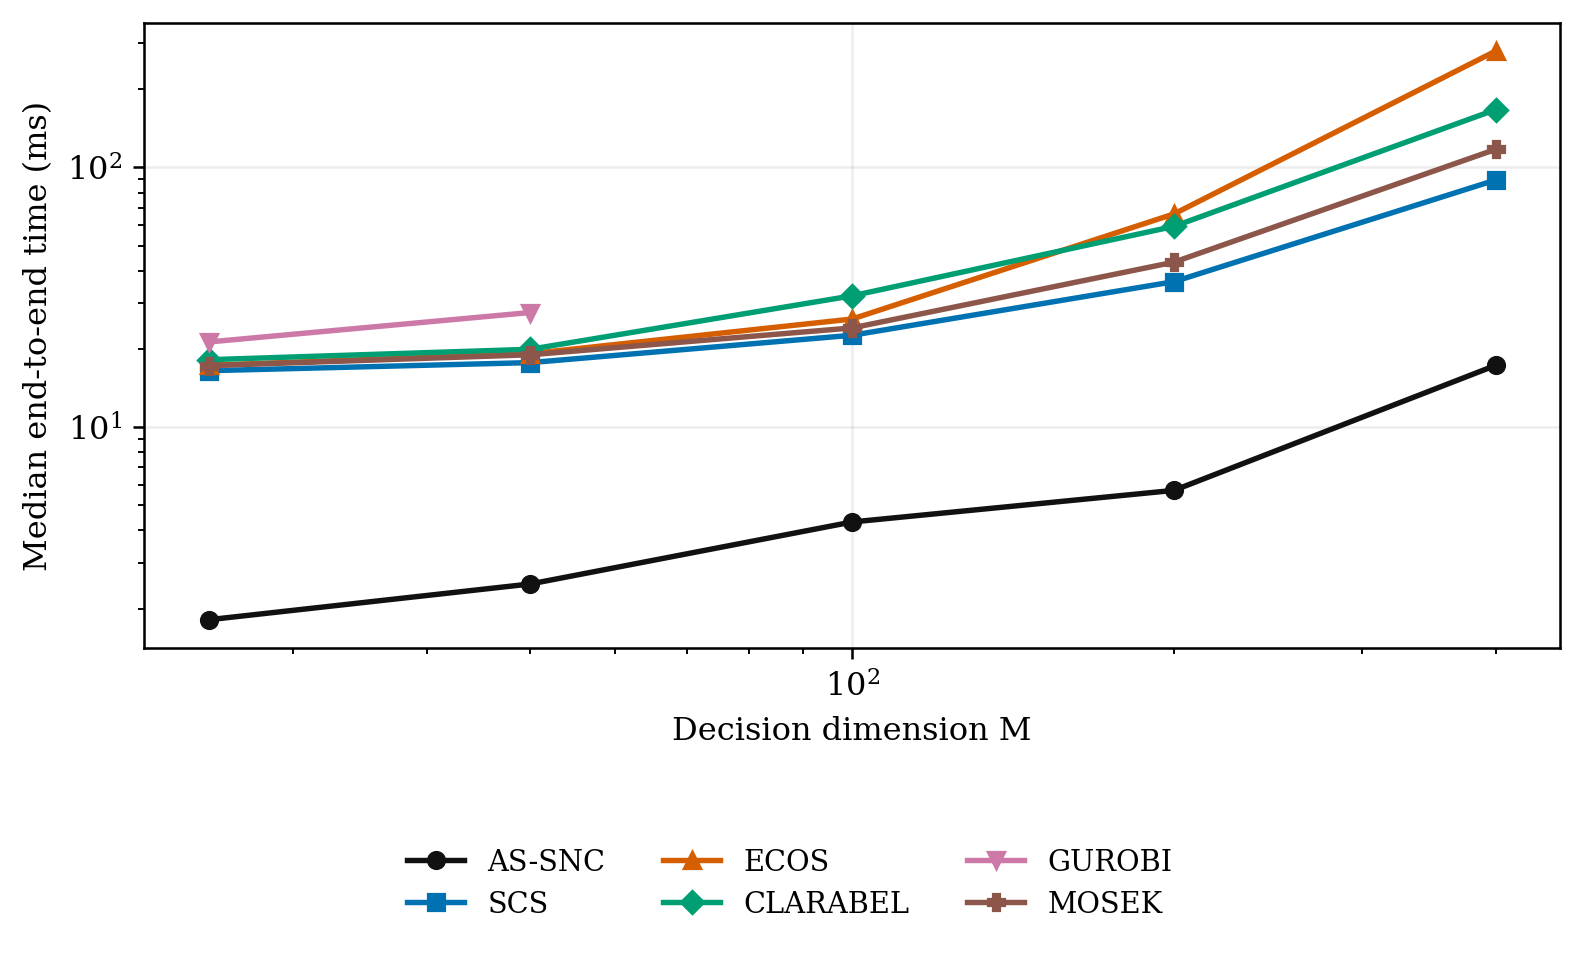

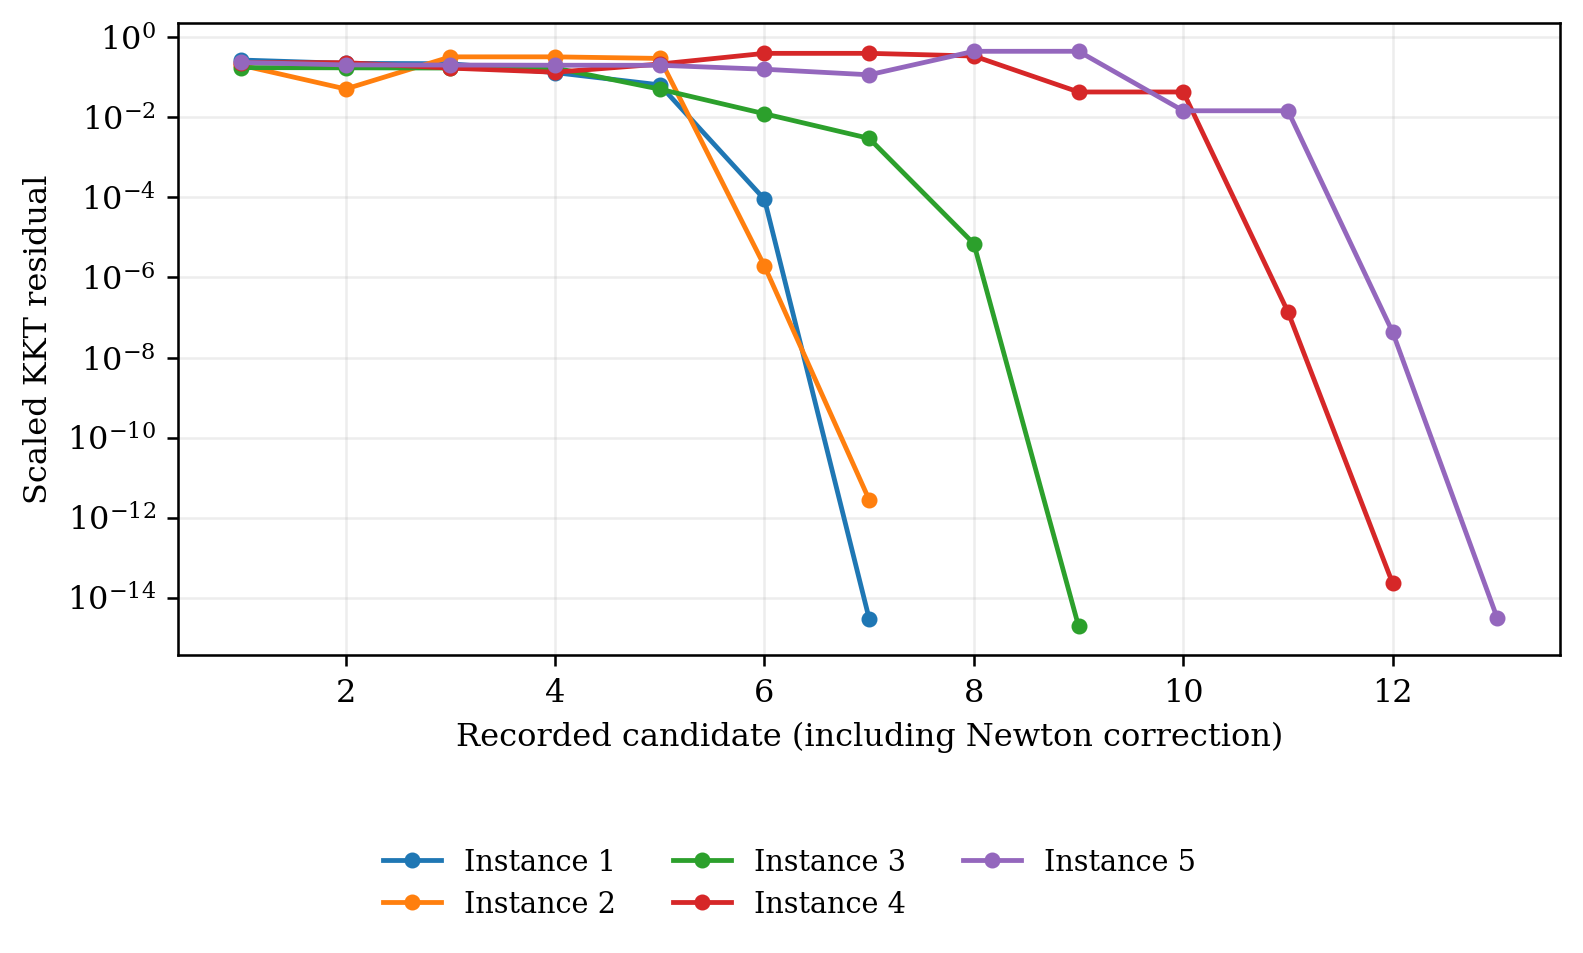

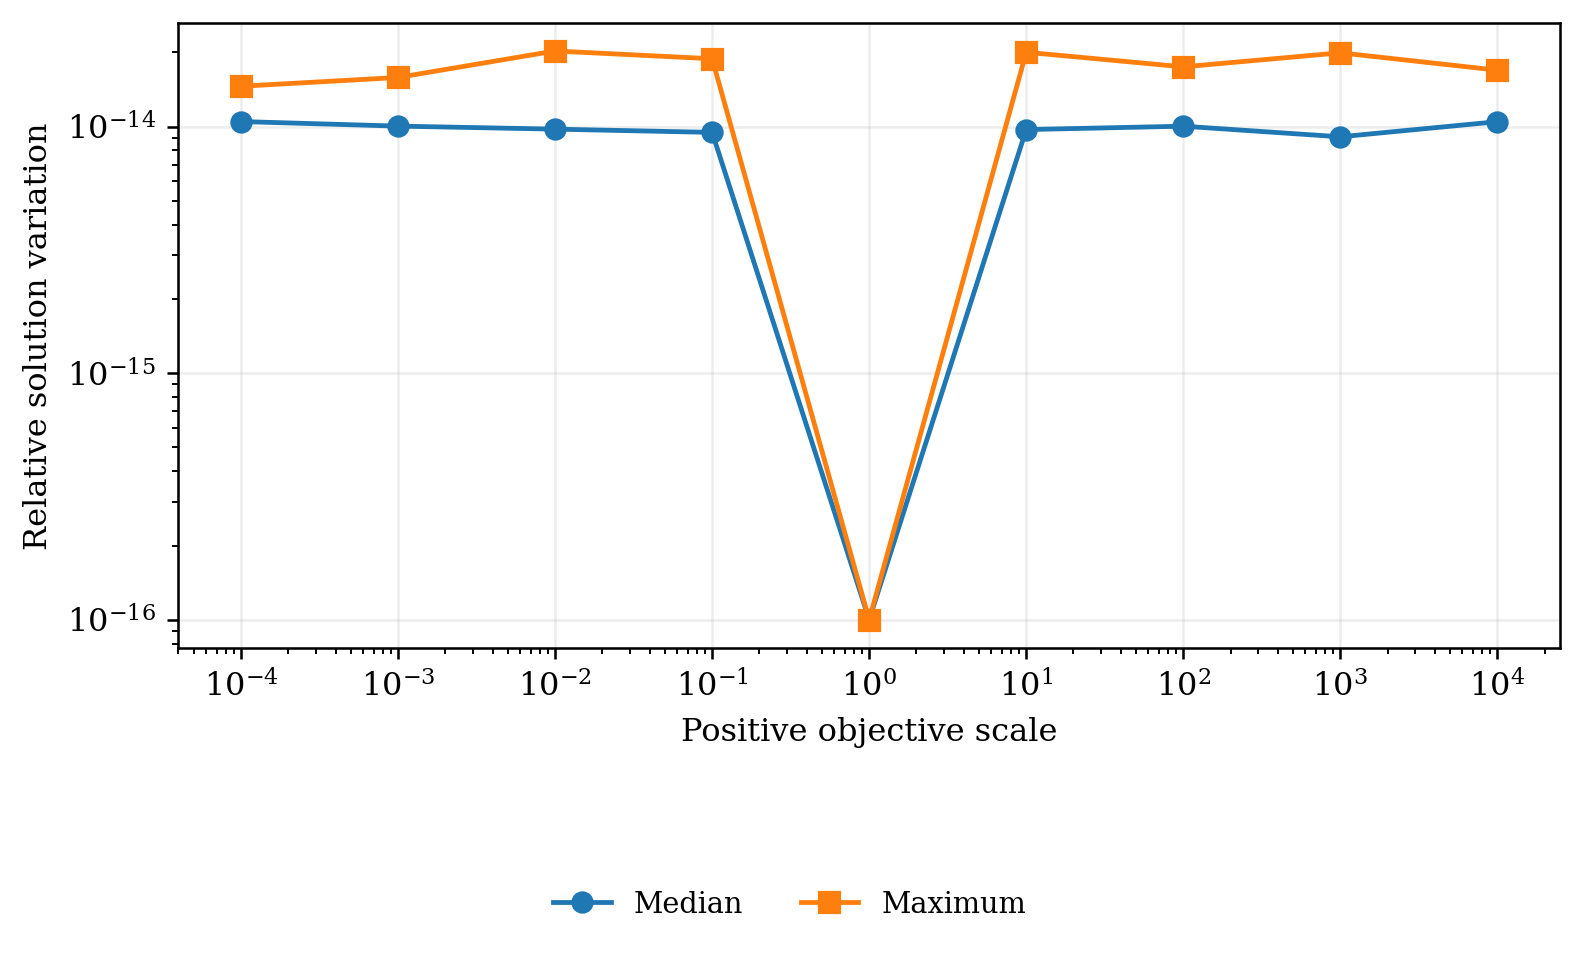

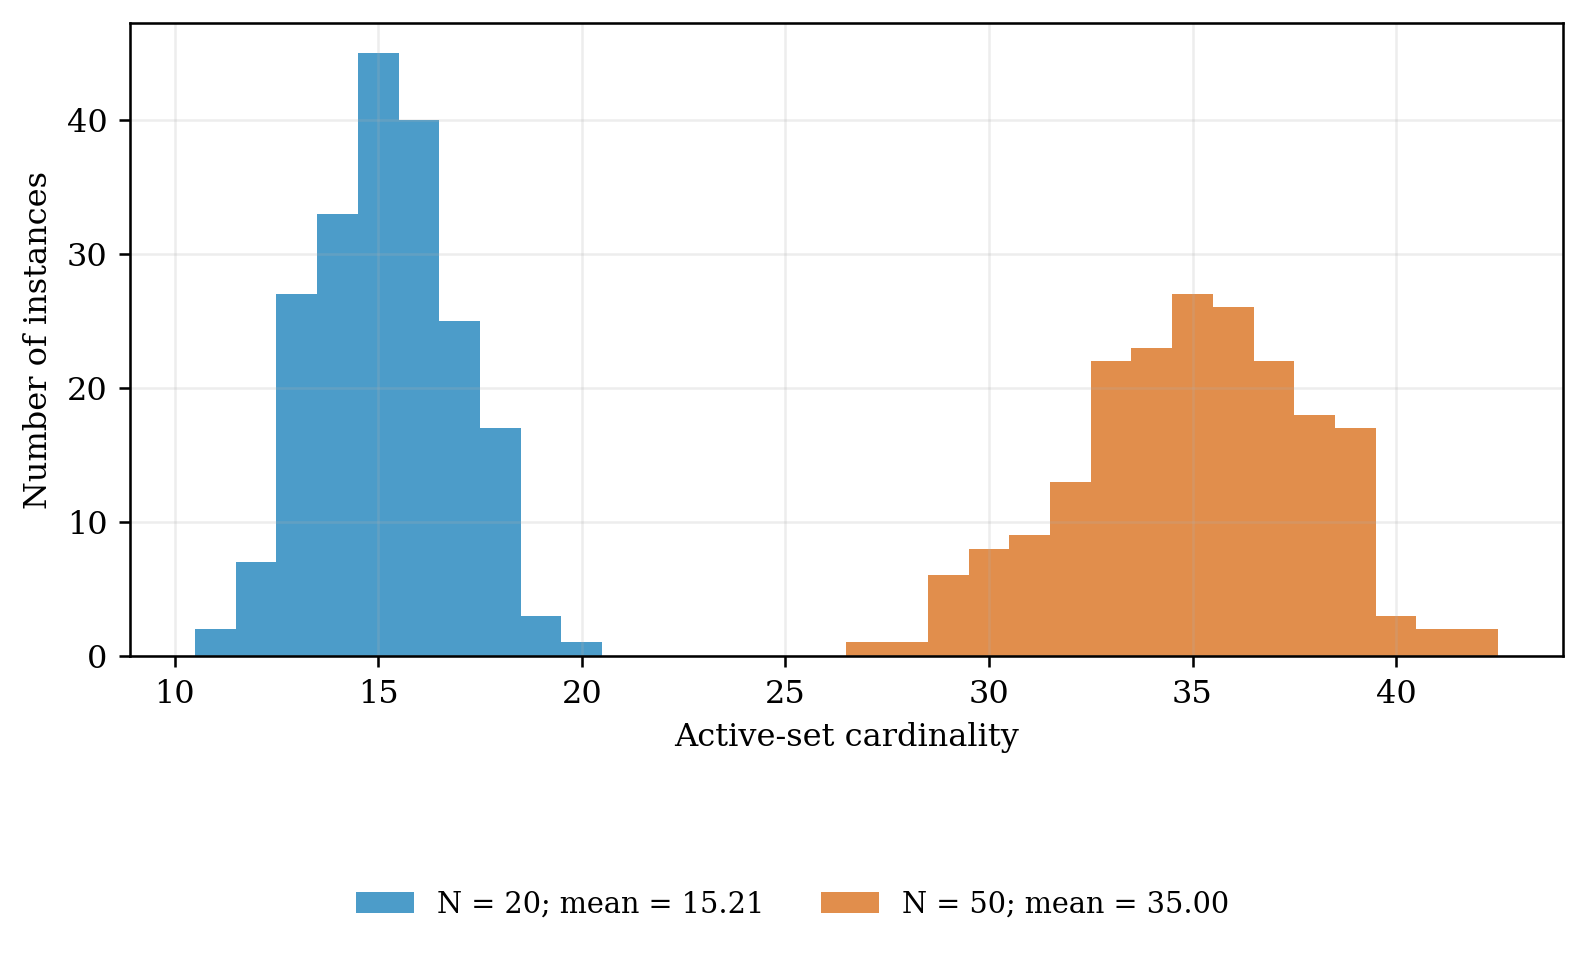

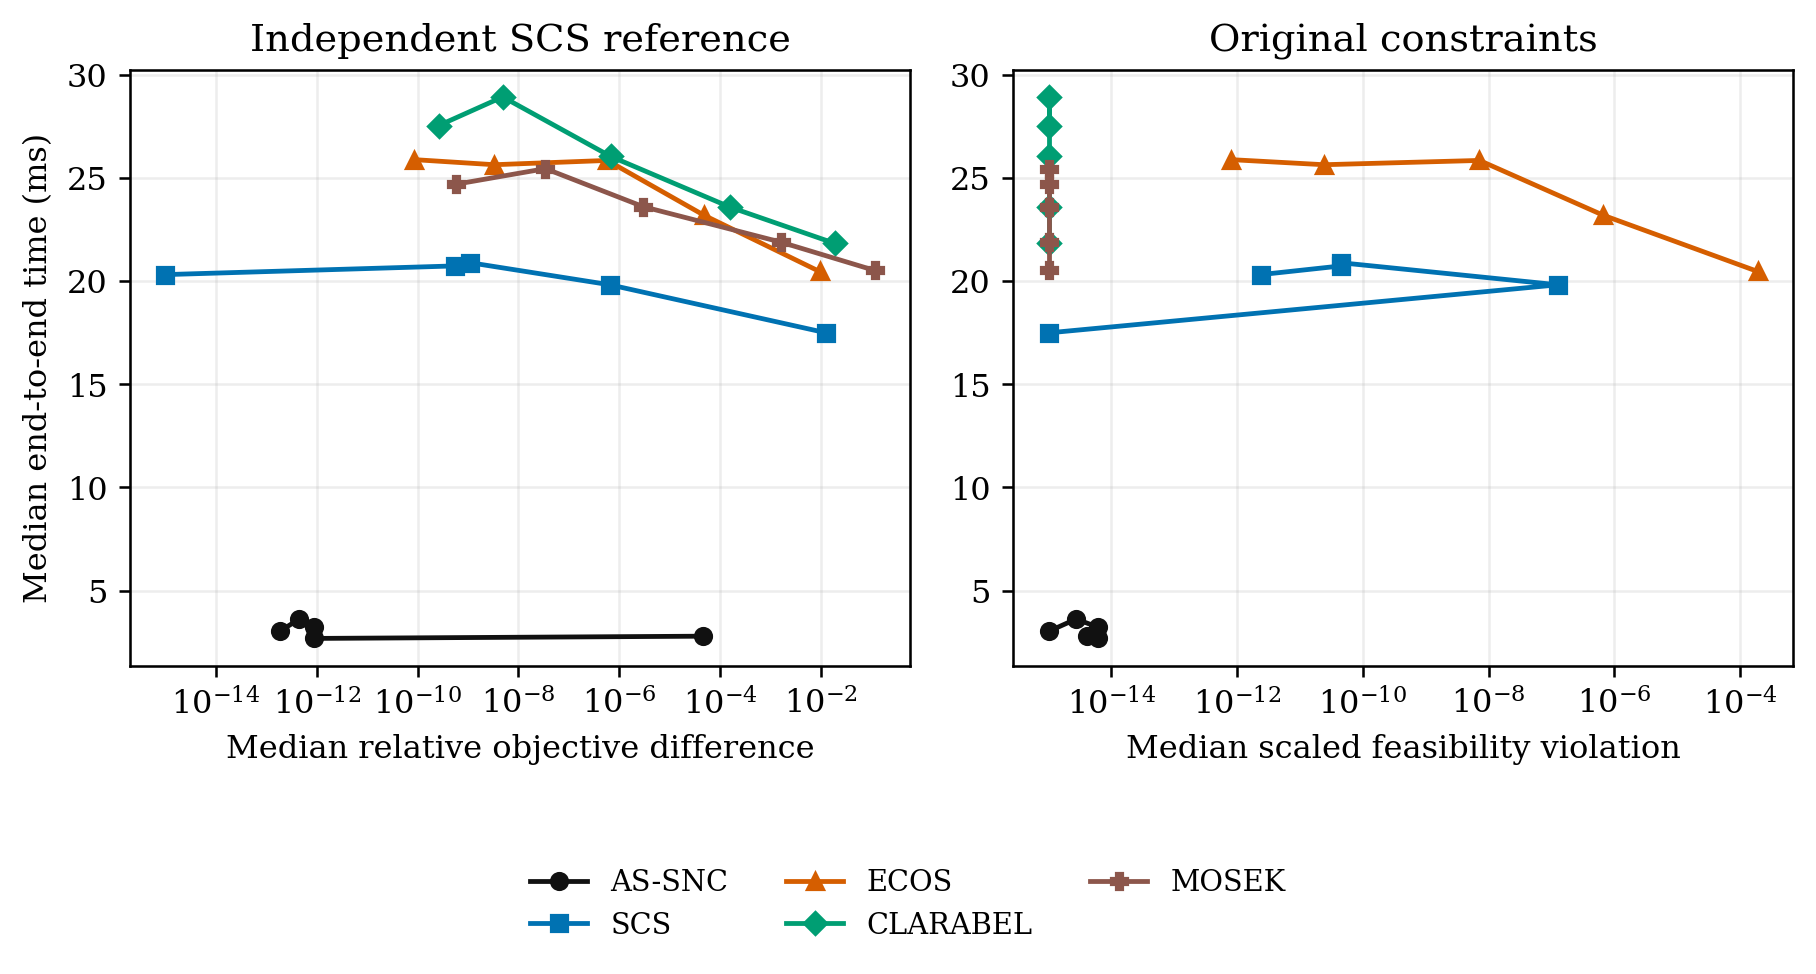

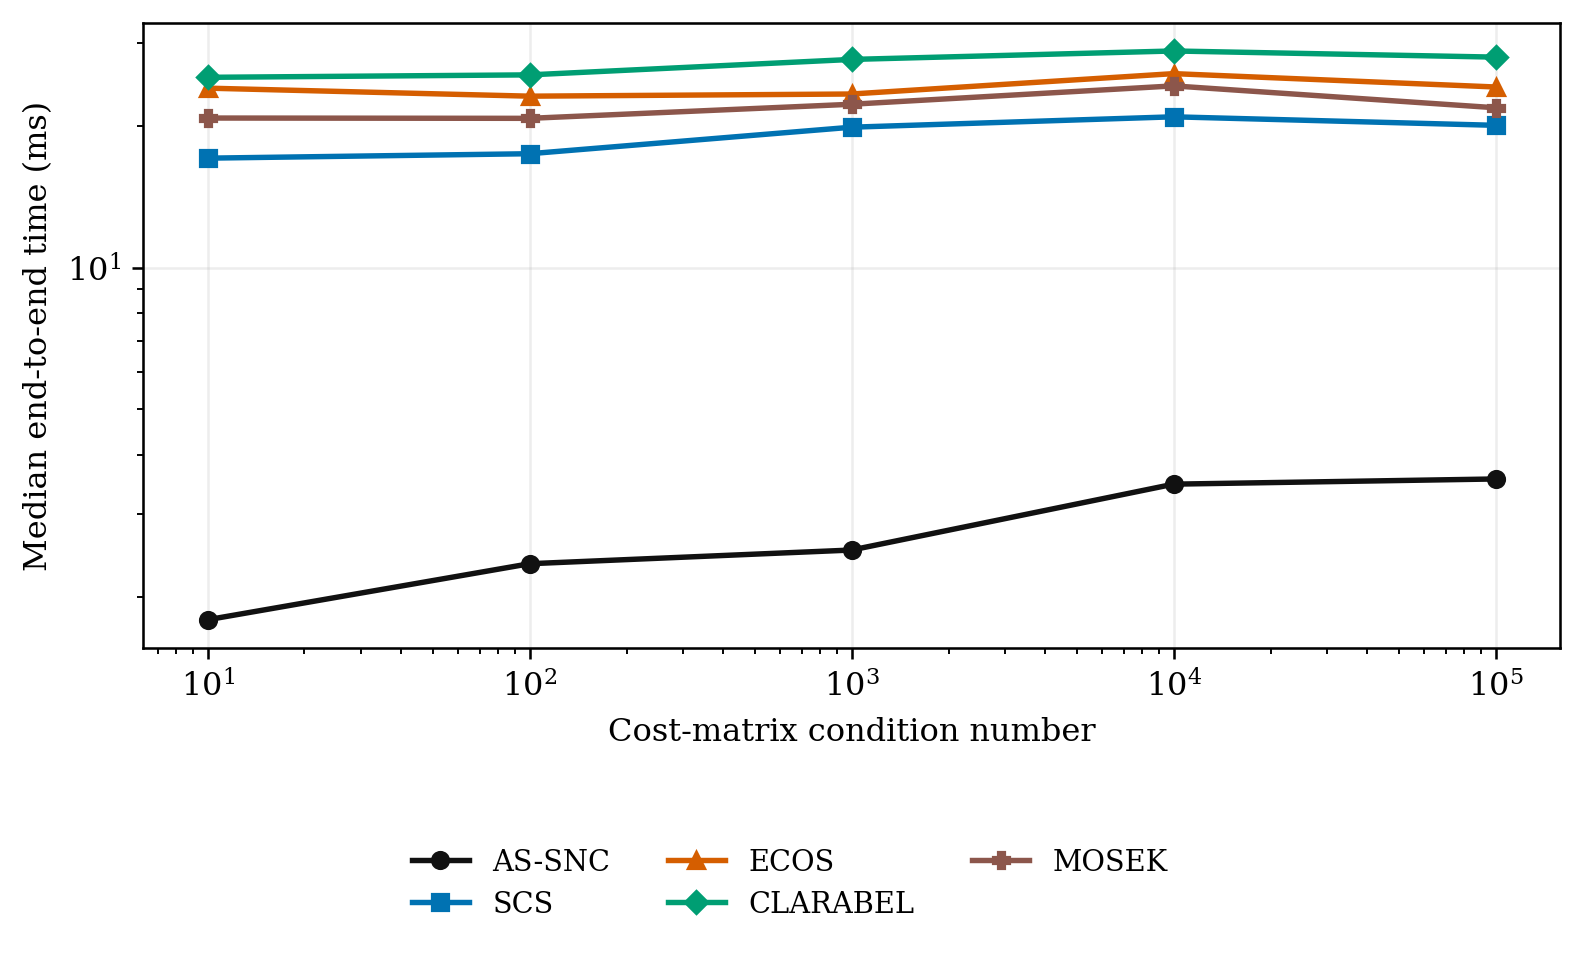

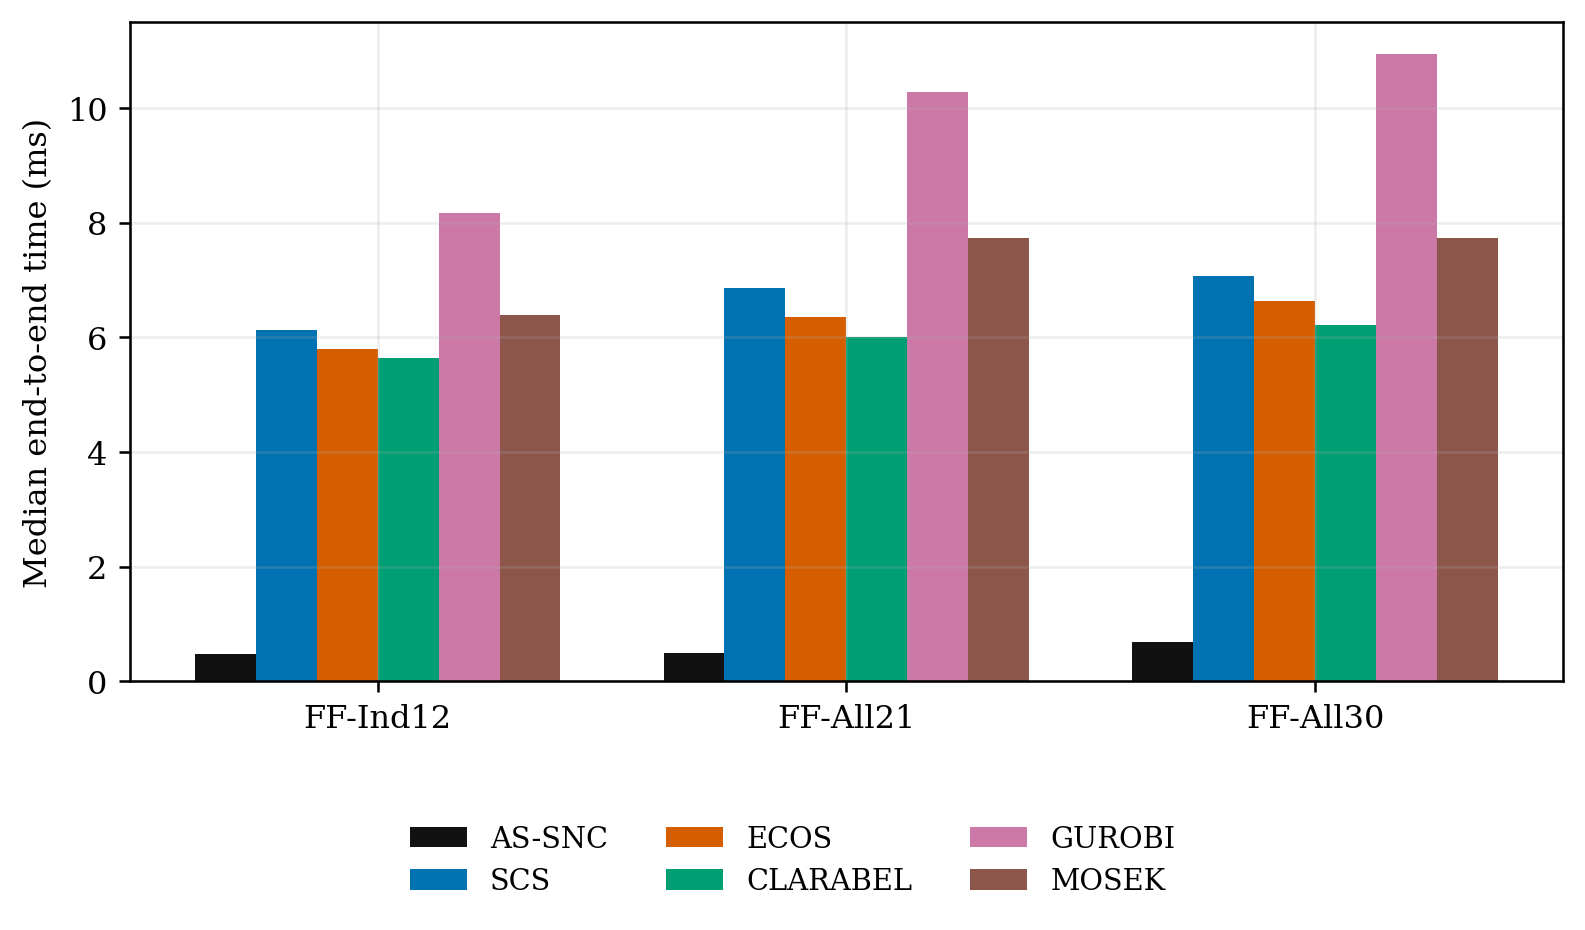

In [9]:
from IPython.display import display, Image
for name in ['fig_scaling.png','fig_convergence.png','fig_scale_invariance.png','fig_active_count.png','fig_pareto.png','fig_conditioning.png','fig_famafrench.png']:
    print(name)
    display(Image(filename=str(OUT/name)))


## Synthetic portfolio illustration
A 50-asset allocation with a three-factor covariance and five sectors of ten assets. The expected-return floor is 0.15 with zero radius; each sector has an exposure floor of 0.02 with a common uncertainty radius κ, swept from 0 to 0.14. The sector floors are feasible only for κ < 1/√50. Each sector direction has entries 0.1 on its ten assets. Each AS-SNC solution is cross-checked against a tight Clarabel solve. The figure (Figure 7 of the paper) shows portfolio risk on the left axis and expected return on the right axis. The illustration is not part of the timing or accuracy benchmarks.

kappa_max = 1/sqrt(50) = 0.1414
kappa=0.000  risk=0.0031  return=0.1500  norm=0.21  |A|=3  AS-SNC  rel_obj_diff=5.6e-08
kappa=0.020  risk=0.0032  return=0.1500  norm=0.20  |A|=6  AS-SNC  rel_obj_diff=1.1e-08
kappa=0.040  risk=0.0040  return=0.1846  norm=0.24  |A|=5  AS-SNC  rel_obj_diff=5.1e-09
kappa=0.060  risk=0.0052  return=0.2349  norm=0.29  |A|=5  AS-SNC  rel_obj_diff=8.4e-10
kappa=0.080  risk=0.0072  return=0.3189  norm=0.38  |A|=5  AS-SNC  rel_obj_diff=1.6e-09
kappa=0.100  risk=0.0115  return=0.4938  norm=0.58  |A|=5  AS-SNC  rel_obj_diff=4.8e-09
kappa=0.120  risk=0.0263  return=1.0890  norm=1.25  |A|=5  AS-SNC  rel_obj_diff=5.1e-07
kappa=0.140  risk=1.0780  return=13.5756  norm=14.91  |A|=5  AS-SNC  rel_obj_diff=1.7e-05
spectral path for all points: True
max relative objective difference to Clarabel: 1.7e-05


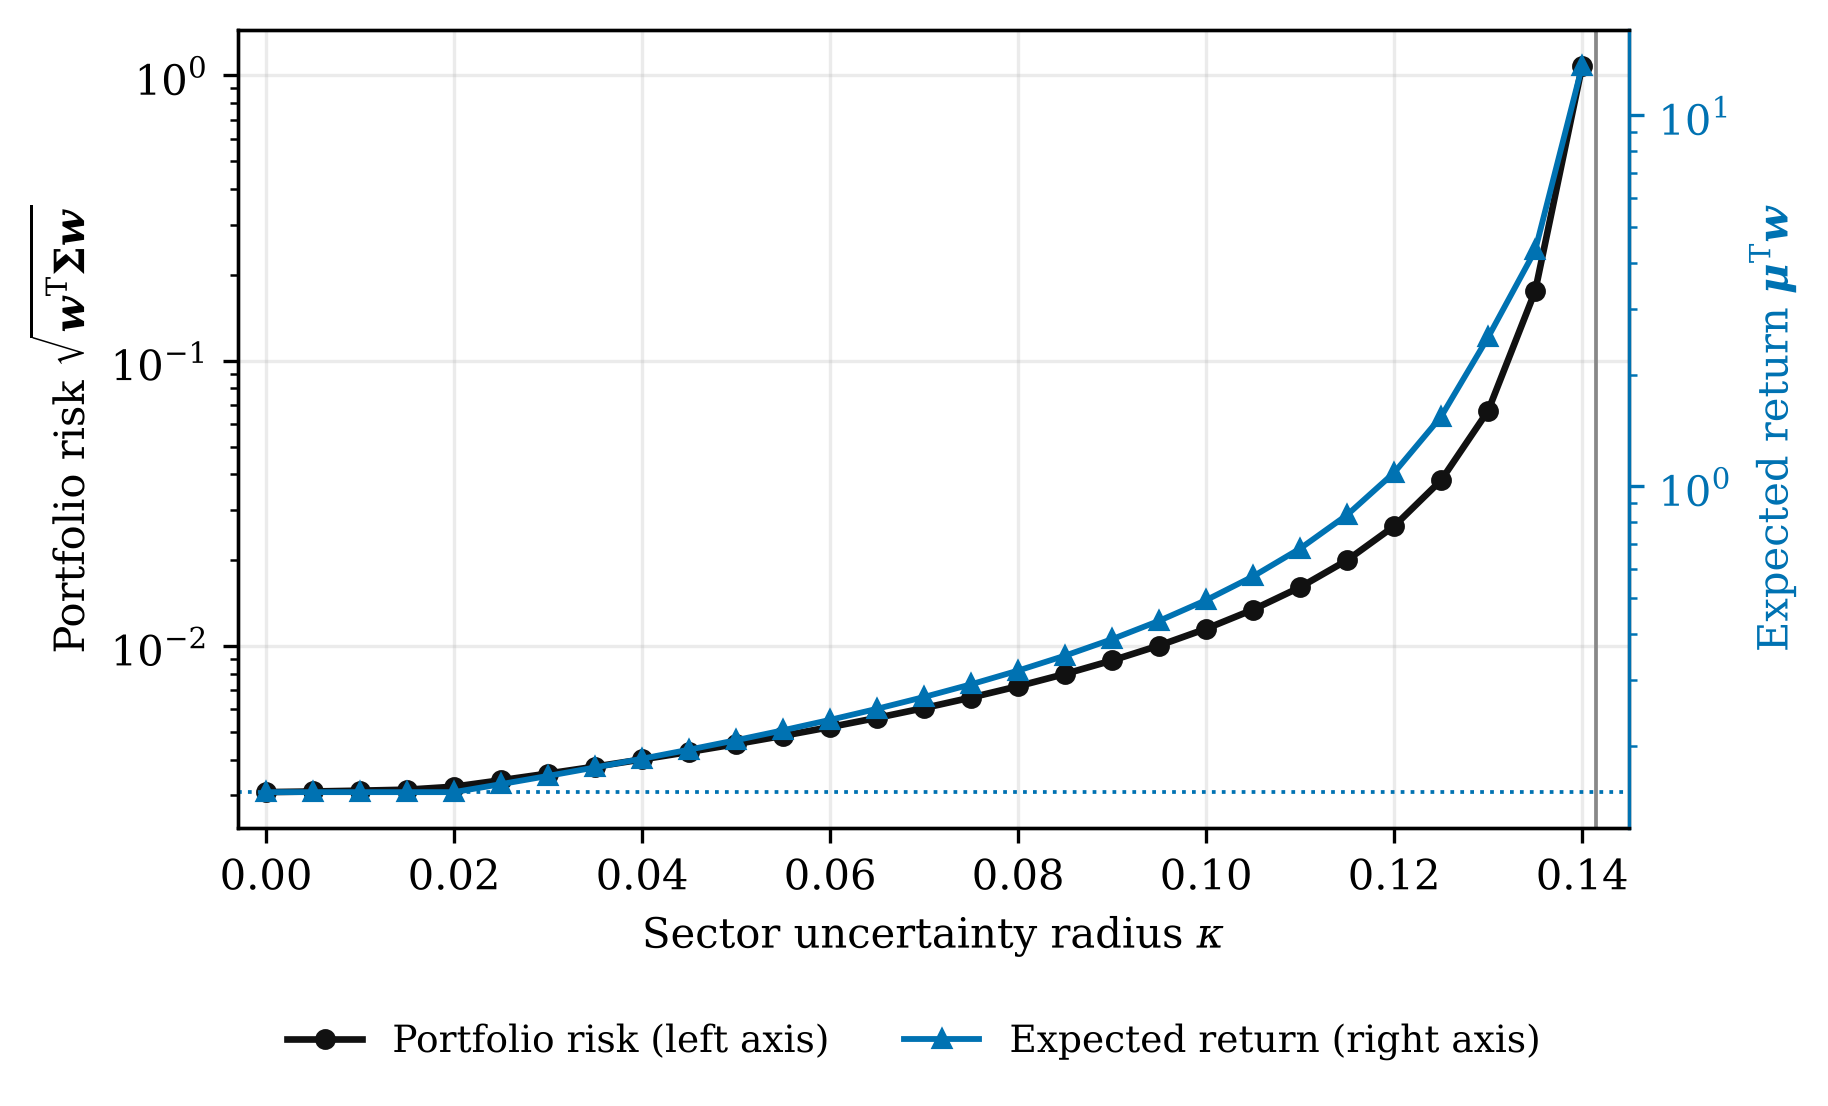

In [ ]:
import json
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Synthetic 50-asset allocation: three-factor covariance, five sectors of ten
# assets, expected-return floor 0.15 with zero radius, sector floors 0.02 with
# common radius kappa. Same model and seed as the near-boundary check above.
rng = np.random.default_rng(2050)
M = 50
F = rng.normal(0, .04, (M, 3))
Q = F @ F.T + np.diag(rng.uniform(.01, .03, M) ** 2)
mu = rng.uniform(.08, .18, M)
Lg = np.zeros((M, 5))
for g in range(5):
    Lg[g * 10:(g + 1) * 10, g] = .1
L = np.column_stack([mu, Lg])
b = np.r_[.15, np.full(5, .02)]
kappa_max = 1 / np.sqrt(50)   # largest sector-exposure-to-norm ratio

def clarabel_check(nu):
    x = cp.Variable(M); t = cp.Variable()
    cs = [cp.norm(x) <= t, L.T @ x - nu * t >= b]
    p = cp.Problem(cp.Minimize(cp.quad_form(x, cp.psd_wrap(Q))), cs)
    p.solve(solver='CLARABEL', tol_gap_abs=1e-12, tol_gap_rel=1e-12,
            tol_feas=1e-12, max_iter=500)
    return x.value

kappas = np.round(np.linspace(0, .14, 29), 3)
rows = []
for k in kappas:
    nu = np.r_[0, np.full(5, k)]
    w, it, A, info = as_snc(Q, L, nu, b, return_info=True)
    wc = clarabel_check(nu)
    obj = float(w @ Q @ w)
    rows.append(dict(kappa=float(k), risk=float(np.sqrt(obj)), ret=float(mu @ w),
                     norm=float(np.linalg.norm(w)), active=int(len(A)),
                     method=info['method'], residual=info['residual'],
                     clarabel_risk=float(np.sqrt(wc @ Q @ wc)),
                     clarabel_residual=quality(Q, L, nu, b, wc)['residual'],
                     rel_obj_diff=abs(obj - float(wc @ Q @ wc)) / obj))
(OUT / 'portfolio.json').write_text(json.dumps(rows, indent=2))

k = np.array([r['kappa'] for r in rows])
BLUE = '#0072B2'
with plt.rc_context({'mathtext.fontset': 'dejavuserif'}):
    fig, ax = plt.subplots(figsize=(6.2, 3.7))
    ax2 = ax.twinx()
    h1, = ax.semilogy(k, [r['risk'] for r in rows], '-o', color='#111111', ms=4, lw=1.6,
                      label='Portfolio risk (left axis)')
    h2, = ax2.semilogy(k, [r['ret'] for r in rows], '-^', color=BLUE, ms=4, lw=1.4,
                       label='Expected return (right axis)')
    ax2.axhline(.15, color=BLUE, lw=.9, ls=':')          # return floor
    ax.axvline(kappa_max, color='#888888', lw=.9)        # feasibility limit 1/sqrt(50)
    ax.set_xlim(-.003, .145)
    ax.set_xlabel(r'Sector uncertainty radius $\kappa$')
    ax.set_ylabel(r'Portfolio risk $\sqrt{\boldsymbol{w}^{\mathrm{T}}\boldsymbol{\Sigma}\boldsymbol{w}}$')
    ax2.set_ylabel(r'Expected return $\boldsymbol{\mu}^{\mathrm{T}}\boldsymbol{w}$', color=BLUE)
    ax2.tick_params(axis='y', which='both', colors=BLUE)
    ax2.spines['right'].set_color(BLUE)
    ax2.grid(False)
    ax.grid(True, which='major', alpha=.25)
    fig.legend([h1, h2], [h1.get_label(), h2.get_label()], loc='lower center', bbox_to_anchor=(.5, 0),
               ncol=2, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, .08, 1, 1))
    fig.savefig(OUT / 'fig_portfolio.png', dpi=300, bbox_inches='tight')
    plt.close(fig)

print('kappa_max = 1/sqrt(50) =', round(kappa_max, 4))
for r in rows[::4]:
    print(f"kappa={r['kappa']:.3f}  risk={r['risk']:.4f}  return={r['ret']:.4f}  norm={r['norm']:.2f}  "
          f"|A|={r['active']}  {r['method']}  rel_obj_diff={r['rel_obj_diff']:.1e}")
print('spectral path for all points:', all(r['method'] == 'AS-SNC' for r in rows))
print('max relative objective difference to Clarabel:', f"{max(r['rel_obj_diff'] for r in rows):.1e}")
display(Image(filename=str(OUT / 'fig_portfolio.png')))


In [11]:
import mosek
print('MOSEK version:', mosek.Env.getversion())
for dataset in ['scaling','conditioning','pareto','famafrench']:
    rows=json.loads((OUT/(dataset+'.json')).read_text())
    rr=[r['methods']['MOSEK'] for r in rows if r['methods']['MOSEK'].get('ms') is not None]
    print(dataset, 'returned',len(rr),'/',len(rows), 'common target',sum(r['passes_common_target'] for r in rr),'/',len(rr))
    if rr: print('max feasibility:',max(r['primal'] for r in rr),'max relative objective difference:',max(r['relative_objective_difference'] for r in rr))
env=json.loads((OUT/'environment.json').read_text())
env['mosek_version']=list(mosek.Env.getversion())
(OUT/'environment.json').write_text(json.dumps(env,indent=2))


MOSEK version: (11, 2, 6)
scaling returned 40 / 40 common target 40 / 40
max feasibility: 3.0763903554243716e-10 max relative objective difference: 2.6767012015357834e-08
conditioning returned 50 / 50 common target 50 / 50
max feasibility: 2.914858729036288e-10 max relative objective difference: 2.4048018526671265e-07
pareto returned 40 / 40 common target 18 / 40
max feasibility: 0.0006291819343787243 max relative objective difference: 0.4233592255374239
famafrench returned 30 / 30 common target 30 / 30
max feasibility: 0.0 max relative objective difference: 7.157634222925472e-08
Out[0]: 204


In [ ]:
import collections
prov=collections.Counter()
for dataset in ['scaling','conditioning','pareto','famafrench']:
    for r in json.loads((OUT/(dataset+'.json')).read_text()):
        prov[(dataset,r['methods']['AS-SNC'].get('method','failed'))]+=1
for (dataset,method),n in sorted(prov.items()):
    print(f'{dataset:13s} {method:18s} {n}')
total=sum(prov.values());spectral=sum(n for (d,m),n in prov.items() if m=='AS-SNC')
print(f'AS-SNC runs: {total}, spectral path: {spectral}, conic fallback: {total-spectral}')


conditioning  AS-SNC             50
famafrench    AS-SNC             30
pareto        AS-SNC             40
scaling       AS-SNC             40
AS-SNC runs: 160, spectral path: 160, conic fallback: 0


## Solver-only timing (Table 4)
Median solve time reported by each backend (`backend_seconds`), excluding CVXPY model construction and canonicalization, for the dimension sweep and the Fama–French runs. AS-SNC times are end-to-end. The last column is the MOSEK-to-AS-SNC ratio; SL marks the restricted-licence size limit. The second block gives the baseline-to-AS-SNC ratios for the conditioning sweep. Values are computed from the stored records; no solver is called.

In [ ]:
import json
import numpy as np

def solver_only(name, key):
    groups = {}
    for r in json.loads((OUT / (name + '.json')).read_text()):
        g = groups.setdefault(key(r), {})
        for m, v in r['methods'].items():
            x = v.get('ms') if m == 'AS-SNC' else (None if v.get('backend_seconds') is None
                                                     else 1e3 * v['backend_seconds'])
            if x is not None:
                g.setdefault(m, []).append(x)
    return {k: {m: float(np.median(x)) for m, x in g.items()} for k, g in groups.items()}

COLS = ['AS-SNC', 'SCS', 'ECOS', 'CLARABEL', 'MOSEK', 'GUROBI']
table4 = {f'M = {k}': v for k, v in solver_only('scaling', lambda r: r['M']).items()}
table4.update(solver_only('famafrench', lambda r: r['case'].rsplit('_', 1)[0]))
print(f"{'Case':10s}" + ''.join(f'{c:>10s}' for c in COLS) + f"{'MOSEK/AS-SNC':>14s}")
for case, v in table4.items():
    cells_ = ''.join(f'{v[c]:10.2f}' if c in v else f"{'SL':>10s}" for c in COLS)
    print(f'{case:10s}' + cells_ + f"{v['MOSEK'] / v['AS-SNC']:14.2f}")

cond = solver_only('conditioning', lambda r: r['case'].rsplit('_', 1)[0])
print()
print('Conditioning sweep, M = 100: baseline / AS-SNC solve-time ratio')
for case, v in cond.items():
    print(f'{case:22s}' + ''.join(f"{c}={v[c] / v['AS-SNC']:.2f}  " for c in COLS[1:] if c in v))
(OUT / 'solver_only.json').write_text(json.dumps(dict(table4=table4, conditioning=cond), indent=2))


Case          AS-SNC       SCS      ECOS  CLARABEL     MOSEK    GUROBI  MOSEK/AS-SNC
M = 25          1.81      0.47      0.95      1.07      1.00      3.60          0.55
M = 50          2.49      0.92      2.74      2.87      1.71      8.97          0.69
M = 100         4.31      2.18      8.76     11.64      5.60        SL          1.30
M = 200         5.70      5.52     41.34     33.96     17.47        SL          3.06
M = 400        17.29     13.71    234.36    116.37     65.88        SL          3.81
FF-Ind12        0.48      0.45      0.12      0.16      0.52      1.06          1.08
FF-All21        0.50      0.58      0.31      0.30      0.76      2.01          1.52
FF-All30        0.68      0.98      0.40      0.59      0.79      2.97          1.15

Conditioning sweep, M = 100: baseline / AS-SNC solve-time ratio
conditioning_k10      SCS=0.32  ECOS=4.88  CLARABEL=5.34  MOSEK=2.67  
conditioning_k100     SCS=0.62  ECOS=3.53  CLARABEL=4.30  MOSEK=1.98  
conditioning_k1000    SCS=0.

## Reproduction archive
The archive contains the eight figures, including the portfolio illustration and its records, the solver-only timing records, complete per-attempt numerical records, reference checks, input hashes, environmental metadata and summary tables. The notebook itself contains the generator, data and complete code.

## Processor record
Run this cell on the measurement machine before building the archive. It adds the processor model to `environment.json`.

In [ ]:
import platform
cpu=platform.processor() or platform.machine()
try:
    cpu=next(l.split(':',1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
except (OSError,StopIteration):
    pass
env=json.loads((OUT/'environment.json').read_text());env['cpu']=cpu
(OUT/'environment.json').write_text(json.dumps(env,indent=2))
print('Recorded processor:',cpu)


In [12]:
import zipfile
with zipfile.ZipFile('AS_SNC_Reproduction_Results.zip','w',zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUT.iterdir()):
        archive.write(path,arcname=path.name)
print('Saved AS_SNC_Reproduction_Results.zip')


Saved AS_SNC_Reproduction_Results.zip
